# SIT307 HD Task: Machine Learning Mini Research
**Paper:** M. Bhagat, A. Sharma, P. Agarwal, *An efficient stacking-based ensemble technique for early heart attack prediction*, Multimedia Tools and Applications 84, 36351-36375 (2025).

**Author:** Akshit Bhullar

This notebook reproduces every number, table and figure in the report. Run top to bottom (`Kernel → Restart & Run All`). Runtime is about 25 min on a laptop CPU.

* **Part 1**: reproduce the paper's six classifiers + stacking on the paper's 1,025-record dataset with its 80/20 hold-out protocol, then critically analyse the result (duplicate-record leakage).
* **Part 2**: **LACS**: *Leakage-Aware, Clinically-encoded, Convex Stacking*, evaluated with 10×5 repeated stratified CV on de-duplicated patients with corrected statistical tests and ablations.

In [1]:
import os, time, json, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.metrics import confusion_matrix, roc_curve, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from scipy.stats import wilcoxon
import sklearn, xgboost
from heartml import *

SEED = 42
np.random.seed(SEED)
os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 200, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#8a8984", "axes.axisbelow": True})
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993"
print("python libs:", "sklearn", sklearn.__version__, "| xgboost", xgboost.__version__, "| pandas", pd.__version__)

python libs: sklearn 1.8.0 | xgboost 3.2.0 | pandas 3.0.2


## 0. Data audit

In [2]:
df = pd.read_csv("data/heart.csv")
print(df.shape); display(df.head())
print("Missing values:", int(df.isna().sum().sum()))
print("Class balance:", df.target.value_counts().to_dict())
rep = duplicate_report(); print(rep)
print("Undocumented codes -> ca==4:", int((df.ca==4).sum()), "| thal==0:", int((df.thal==0).sum()))
json.dump(rep, open("results/duplicate_report.json", "w"), indent=2)

(1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


Missing values: 0
Class balance: {1: 526, 0: 499}
{'rows': 1025, 'duplicate_rows': 723, 'unique_rows': 302, 'unique_rows_with_conflicting_labels': 0}
Undocumented codes -> ca==4: 18 | thal==0: 7


## Part 1: Reproduction of the paper
Paper protocol (from the paper): 1,025 records, 13 features, missing-value filling, standardisation, categorical encoding, train/test hold-out, six classifiers (LR, DT, RF, XGB, NB, KNN), then stacking with a meta-classifier.

The reported accuracies (RF = DT = 92.68 %, XGB = 90.73 %, stacking = 98.53 %) are all multiples of 1/205, so the test set had **205 records → an 80/20 split** of 1,025. Hyperparameters and the meta-learner are not reported → library defaults and a logistic-regression meta-learner (the standard choice) are assumed.

In [3]:
X, y = load_data()
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train", Xtr.shape, "test", Xte.shape)
rows, fitted = [], {}
for name, m in paper_base_models(SEED) + [("Stacking", paper_stacking(SEED))]:
    m.fit(Xtr, ytr); p = m.predict_proba(Xte)[:, 1]; fitted[name] = (m, p)
    rows.append({"Model": name, **scores(yte, p)})
rep1 = pd.DataFrame(rows).set_index("Model")
paper = pd.Series({"LR": np.nan, "DT": 92.68, "RF": 92.68, "XGB": 90.73, "NB": np.nan, "KNN": np.nan, "Stacking": 98.53})
rep1.insert(0, "Paper Acc (%)", paper)
out = rep1.copy(); out[METRICS + ["LogLoss", "Brier"]] = out[METRICS + ["LogLoss", "Brier"]].round(4)
out.to_csv("results/part1_single_split.csv"); out

train (820, 13) test (205, 13)


,Paper Acc (%),Accuracy,Precision,Recall,F1,AUC,LogLoss,Brier
Model,,,,,,,,
LR,NaN,0.8098,0.7619,0.9143,0.8312,0.9298,0.3483,0.1114
DT,92.68,0.9854,1.0000,0.9714,0.9855,0.9857,0.2022,0.0146
RF,92.68,1.0000,1.0000,1.0000,1.0000,1.0000,0.0587,0.0072
XGB,90.73,1.0000,1.0000,1.0000,1.0000,1.0000,0.0139,0.0006
NB,NaN,0.8293,0.8070,0.8762,0.8402,0.9043,0.5061,0.1361
KNN,NaN,0.8634,0.8738,0.8571,0.8654,0.9629,0.2170,0.0800
Stacking,98.53,1.0000,1.0000,1.0000,1.0000,1.0000,0.0144,0.0007


### 1.1 Variance across 30 random splits (same paper protocol)

In [4]:
t = time.time(); rs = []
for s in range(30):
    a, b, c, d = train_test_split(X, y, test_size=0.2, stratify=y, random_state=s)
    seen = test_rows_seen_in_train(a, b)
    for name, m in paper_base_models(s) + [("Stacking", paper_stacking(s))]:
        p = m.fit(a, c).predict_proba(b)[:, 1]
        rs.append({"seed": s, "Model": name, "seen_frac": seen.mean(), **scores(d, p)})
rs = pd.DataFrame(rs); rs.to_csv("results/part1_30_splits_raw.csv", index=False)
summ = rs.groupby("Model", sort=False)[METRICS].agg(["mean", "std"]).round(4)
summ.to_csv("results/part1_30_splits_summary.csv")
print(f"{time.time()-t:.0f}s | mean fraction of test rows with an exact copy in train: {rs.seen_frac.mean():.3f}")
summ

42s | mean fraction of test rows with an exact copy in train: 0.973


Accuracy         Precision          Recall              F1          \
             mean     std      mean     std    mean     std    mean     std   
Model                                                                         
LR         0.8372  0.0244    0.8066  0.0298  0.8994  0.0351  0.8498  0.0225   
DT         0.9917  0.0099    0.9956  0.0114  0.9883  0.0147  0.9919  0.0097   
RF         0.9958  0.0085    0.9957  0.0114  0.9962  0.0099  0.9959  0.0082   
XGB        0.9948  0.0096    0.9948  0.0144  0.9952  0.0132  0.9949  0.0093   
NB         0.8161  0.0200    0.7987  0.0225  0.8581  0.0339  0.8268  0.0196   
KNN        0.8472  0.0209    0.8485  0.0384  0.8578  0.0368  0.8519  0.0188   
Stacking   0.9943  0.0094    0.9956  0.0114  0.9933  0.0123  0.9944  0.0092   

             AUC          
            mean     std  
Model                     
LR        0.9135  0.0163  
DT        0.9918  0.0099  
RF        0.9995  0.0011  
XGB       0.9969  0.0076  
NB        0.8989  0.0180  
KNN       0.9561  0.0116  
Stacking  0.9989  0.0025

### 1.2 Critical analysis: duplicate-record leakage
Only **302 of the 1,025 records are unique**; 723 are exact duplicates. With a random 80/20 split almost every test record has an identical twin in the training set, so the hold-out score measures memorisation, not generalisation. We re-run the *identical* paper pipeline after removing duplicates.

In [5]:
Xd, yd = load_data(deduplicate=True)
print("Deduplicated:", Xd.shape, "class balance:", np.bincount(yd))
rd = []
for s in range(30):
    a, b, c, d = train_test_split(Xd, yd, test_size=0.2, stratify=yd, random_state=s)
    for name, m in paper_base_models(s) + [("Stacking", paper_stacking(s))]:
        rd.append({"seed": s, "Model": name, **scores(d, m.fit(a, c).predict_proba(b)[:, 1])})
rd = pd.DataFrame(rd); rd.to_csv("results/part1_dedup_30_splits_raw.csv", index=False)
cmp = pd.DataFrame({"Paper reported": paper / 100,
                    "Reproduced (leaky, 30 splits)": rs.groupby("Model", sort=False).Accuracy.mean(),
                    "De-duplicated (30 splits)": rd.groupby("Model", sort=False).Accuracy.mean(),
                    "De-dup SD": rd.groupby("Model", sort=False).Accuracy.std()}).round(4)
cmp.to_csv("results/part1_leakage_comparison.csv"); cmp

Deduplicated: (302, 13) class balance: [138 164]


,Paper reported,"Reproduced (leaky, 30 splits)",De-duplicated (30 splits),De-dup SD
LR,NaN,0.8372,0.8377,0.0425
DT,0.9268,0.9917,0.7601,0.0505
RF,0.9268,0.9958,0.8197,0.0479
XGB,0.9073,0.9948,0.8131,0.0372
NB,NaN,0.8161,0.8148,0.0444
KNN,NaN,0.8472,0.8295,0.0403
Stacking,0.9853,0.9943,0.8459,0.0384


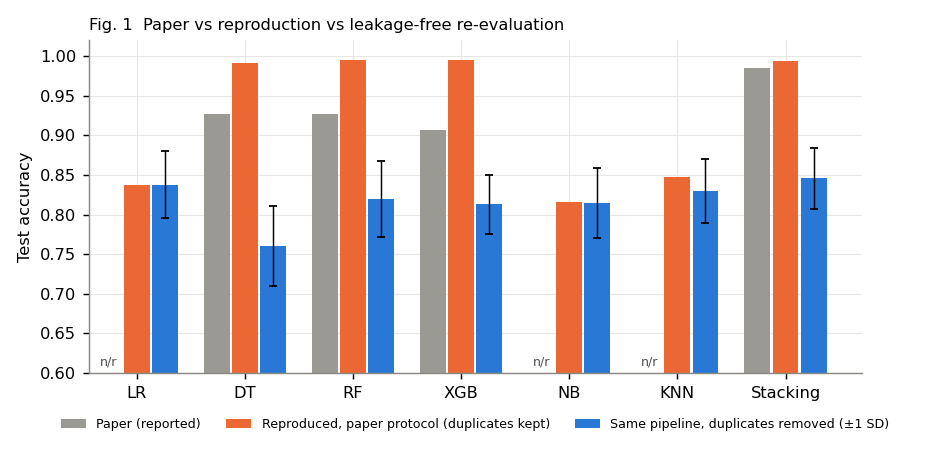

In [6]:
order = ["LR", "DT", "RF", "XGB", "NB", "KNN", "Stacking"]
fig, ax = plt.subplots(figsize=(7.2, 3.5)); x = np.arange(len(order)); w = 0.26
ax.bar(x - w, paper.reindex(order) / 100, w - 0.02, color=GREY, label="Paper (reported)")
ax.bar(x, cmp.loc[order, "Reproduced (leaky, 30 splits)"], w - 0.02, color=ORANGE, label="Reproduced, paper protocol (duplicates kept)")
ax.bar(x + w, cmp.loc[order, "De-duplicated (30 splits)"], w - 0.02, yerr=cmp.loc[order, "De-dup SD"], capsize=2,
       color=BLUE, error_kw={"elinewidth": .8}, label="Same pipeline, duplicates removed (±1 SD)")
for i, m in enumerate(order):
    if np.isnan(paper[m]): ax.text(i - w, 0.61, "n/r", ha="center", fontsize=7, color="#52514e")
ax.set_xticks(x, order); ax.set_ylim(0.6, 1.02); ax.set_ylabel("Test accuracy")
ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False, ncol=3); ax.set_title("Fig. 1  Paper vs reproduction vs leakage-free re-evaluation", loc="left", fontsize=9)
plt.tight_layout(); plt.savefig("figures/fig1_leakage.png"); plt.show()

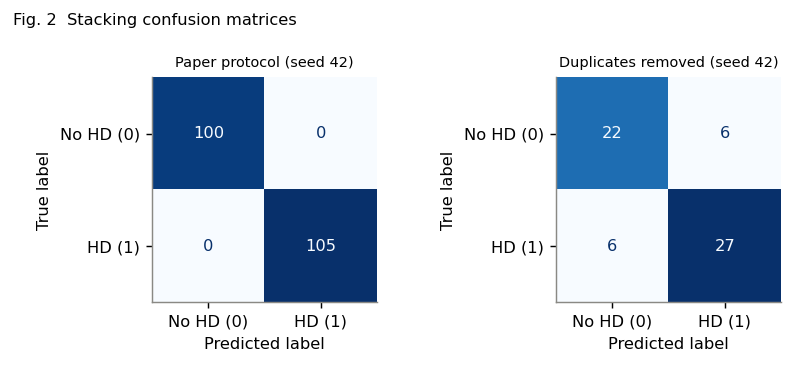

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.8))
for ax, (ttl, yy, pp) in zip(axs, [("Paper protocol (seed 42)", yte, fitted["Stacking"][1]),
                                   ("Duplicates removed (seed 42)", None, None)]):
    if yy is None:
        a, b, c, d = train_test_split(Xd, yd, test_size=0.2, stratify=yd, random_state=SEED)
        yy, pp = d, paper_stacking(SEED).fit(a, c).predict_proba(b)[:, 1]
    ConfusionMatrixDisplay(confusion_matrix(yy, pp >= .5), display_labels=["No HD (0)", "HD (1)"]).plot(
        ax=ax, cmap="Blues", colorbar=False); ax.grid(False); ax.set_title(ttl, fontsize=8)
fig.suptitle("Fig. 2  Stacking confusion matrices", x=0.02, ha="left", fontsize=9)
plt.tight_layout(); plt.savefig("figures/fig2_confusion.png"); plt.show()

## Part 2: Proposed method: LACS
**Limitations addressed**
1. *Evaluation leakage*: duplicates cross the split → evaluate on unique patients with 10×5 repeated stratified CV (identical folds for every model) and corrected tests.
2. *Clinically wrong encoding*: `cp`, `restecg`, `slope`, `thal` are nominal codes but were fed as ordered numbers; `ca = 4` and `thal = 0` are undocumented codes that stand for missing values in the original UCI data → convert to NaN, impute inside the fold, one-hot encode nominals.
3. *Over-flexible meta-learner*: an unconstrained LR meta-learner on six highly correlated base outputs overfits with ~240 training patients → **convex, shrunk meta-weights** learned from inner out-of-fold probabilities over a diverse, regularised base pool (LR with inner-CV-tuned C, RBF-SVM, KNN, NB, RF, ExtraTrees, shallow XGBoost).

**Ablations (same folds):** paper stacking + clinical encoding (isolates encoding), convex weights without shrinkage, uniform soft-voting (shrink = 1), and the best single base learner (clinical LR).

In [8]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
folds = list(cv.split(Xd, yd)); print(len(folds), "folds")

def paper_stack_clinical(s):
    base = [(n, make_pipeline(clinical_preprocessor(), m if not hasattr(m, "steps") else m.steps[-1][1]))
            for n, m in paper_base_models(s)]
    return StackingClassifier(base, final_estimator=LogisticRegression(max_iter=1000),
                              cv=StratifiedKFold(5, shuffle=True, random_state=s), stack_method="predict_proba")

per_fold, oof_rep0, W = [], {}, []
t = time.time()
for i, (tr, te) in enumerate(folds):
    A, B, a, b = Xd.iloc[tr], Xd.iloc[te], yd[tr], yd[te]
    preds = {}
    preds["Paper stacking (baseline)"] = paper_stacking(i).fit(A, a).predict_proba(B)[:, 1]
    preds["Paper best single (RF)"] = paper_base_models(i)[2][1].fit(A, a).predict_proba(B)[:, 1]
    preds["Ablation: paper stacking + clinical enc."] = paper_stack_clinical(i).fit(A, a).predict_proba(B)[:, 1]
    lacs = ConvexStacking(shrink=0.5, seed=i).fit(A, a)
    Pb = np.column_stack([m.predict_proba(B)[:, 1] for m in lacs.bases_])
    k = Pb.shape[1]
    preds["LACS (proposed)"] = Pb @ lacs.weights_
    preds["Ablation: convex, no shrinkage"] = Pb @ lacs.raw_weights_
    preds["Ablation: uniform soft vote"] = Pb.mean(1)
    preds["Ablation: clinical LR only"] = Pb[:, lacs.names_.index("LR")]
    W.append(lacs.weights_)
    for mname, p in preds.items():
        per_fold.append({"fold": i, "Model": mname, **scores(b, p)})
        if i < 5: oof_rep0.setdefault(mname, np.zeros(len(yd)))[te] = p
    if i % 10 == 9: print(f"fold {i+1}/50  {time.time()-t:.0f}s")
pf = pd.DataFrame(per_fold); pf.to_csv("results/part2_per_fold.csv", index=False)
weights = pd.DataFrame(W, columns=lacs.names_); weights.to_csv("results/part2_lacs_weights.csv", index=False)

50 folds


fold 10/50  132s


fold 20/50  262s


fold 30/50  391s


fold 40/50  522s


fold 50/50  651s


In [9]:
order2 = ["Paper stacking (baseline)", "Paper best single (RF)", "Ablation: paper stacking + clinical enc.",
          "Ablation: uniform soft vote", "Ablation: convex, no shrinkage", "Ablation: clinical LR only", "LACS (proposed)"]
M = METRICS + ["LogLoss", "Brier"]
g = pf.groupby("Model")[M]
tab = g.mean().round(4).astype(str) + " ± " + g.std().round(3).astype(str)
tab = tab.loc[order2]; tab.to_csv("results/part2_summary.csv"); tab

,Accuracy,Precision,Recall,F1,AUC,LogLoss,Brier
Model,,,,,,,
Paper stacking (baseline),0.8314 ± 0.039,0.8261 ± 0.048,0.8788 ± 0.05,0.85 ± 0.033,0.9055 ± 0.031,0.3987 ± 0.06,0.1238 ± 0.023
Paper best single (RF),0.8176 ± 0.045,0.8145 ± 0.049,0.8647 ± 0.061,0.8371 ± 0.04,0.9027 ± 0.031,0.4075 ± 0.051,0.1282 ± 0.018
Ablation: paper stacking + clinical enc.,0.8357 ± 0.038,0.832 ± 0.041,0.8775 ± 0.057,0.8527 ± 0.034,0.9069 ± 0.029,0.3893 ± 0.051,0.1195 ± 0.02
Ablation: uniform soft vote,0.8444 ± 0.031,0.8317 ± 0.036,0.8976 ± 0.057,0.8619 ± 0.029,0.9124 ± 0.028,0.3788 ± 0.048,0.1176 ± 0.017
"Ablation: convex, no shrinkage",0.8493 ± 0.032,0.8394 ± 0.035,0.8963 ± 0.056,0.8655 ± 0.03,0.9117 ± 0.029,0.3793 ± 0.05,0.1175 ± 0.018
Ablation: clinical LR only,0.8549 ± 0.03,0.8428 ± 0.037,0.9042 ± 0.052,0.871 ± 0.027,0.9162 ± 0.029,0.3722 ± 0.049,0.1148 ± 0.018
LACS (proposed),0.8463 ± 0.03,0.8345 ± 0.034,0.8975 ± 0.057,0.8633 ± 0.029,0.9128 ± 0.029,0.3779 ± 0.049,0.117 ± 0.018


### 2.1 Statistical tests (Nadeau and Bengio corrected resampled t-test and Wilcoxon signed-rank; 50 paired folds)

In [10]:
n_te = len(folds[0][1]); n_tr = len(folds[0][0]); tests = []
for other in order2[:-1]:
    for met in M:
        a_ = pf[pf.Model == "LACS (proposed)"].sort_values("fold")[met].values
        b_ = pf[pf.Model == other].sort_values("fold")[met].values
        d, tt, p = corrected_resampled_ttest(a_, b_, n_tr, n_te)
        try: pw = wilcoxon(a_, b_).pvalue
        except ValueError: pw = np.nan
        tests.append({"LACS vs": other, "Metric": met, "Mean diff": round(d, 4), "t (corrected)": round(tt, 3),
                      "p (corrected t)": round(p, 4), "p (Wilcoxon)": round(pw, 4)})
tests = pd.DataFrame(tests); tests.to_csv("results/part2_stat_tests.csv", index=False)
tests[tests.Metric.isin(["Accuracy", "F1", "AUC", "LogLoss"])].pivot(index="LACS vs", columns="Metric", values="p (corrected t)").loc[order2[:-1]]

Metric,AUC,Accuracy,F1,LogLoss
LACS vs,,,,
Paper stacking (baseline),0.4356,0.3689,0.3727,0.2514
Paper best single (RF),0.2526,0.1498,0.1507,0.1017
Ablation: paper stacking + clinical enc.,0.3787,0.4587,0.4449,0.2417
Ablation: uniform soft vote,0.8748,0.7899,0.8388,0.8034
"Ablation: convex, no shrinkage",0.6275,0.7741,0.8139,0.7005
Ablation: clinical LR only,0.4522,0.4578,0.4603,0.4079


In [11]:
tests[tests["LACS vs"] == "Paper stacking (baseline)"]

,LACS vs,Metric,Mean diff,t (corrected),p (corrected t),p (Wilcoxon)
0,Paper stacking (baseline),Accuracy,0.0149,0.907,0.3689,0.0051
1,Paper stacking (baseline),Precision,0.0084,0.531,0.5981,0.0550
2,Paper stacking (baseline),Recall,0.0188,0.861,0.3932,0.0031
3,Paper stacking (baseline),F1,0.0133,0.900,0.3727,0.0037
4,Paper stacking (baseline),AUC,0.0074,0.786,0.4356,0.0126
5,Paper stacking (baseline),LogLoss,-0.0207,-1.161,0.2514,0.0002
6,Paper stacking (baseline),Brier,-0.0068,-0.997,0.3237,0.0022


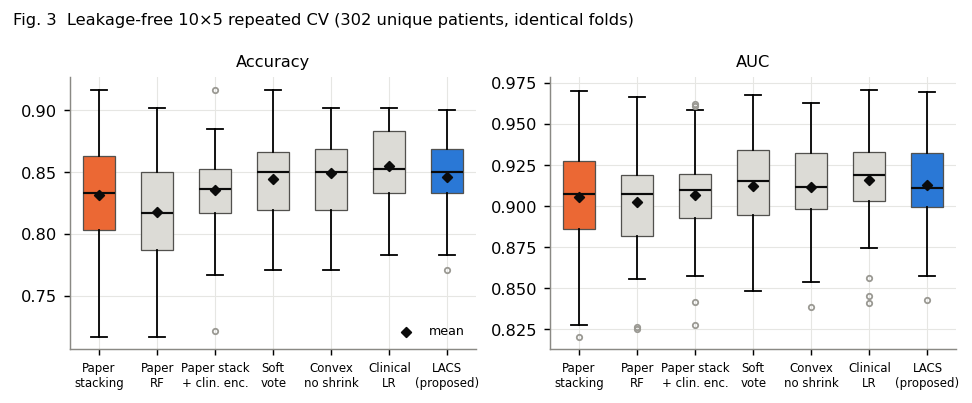

In [12]:
short = {"Paper stacking (baseline)": "Paper\nstacking", "Paper best single (RF)": "Paper\nRF",
         "Ablation: paper stacking + clinical enc.": "Paper stack\n+ clin. enc.", "Ablation: uniform soft vote": "Soft\nvote",
         "Ablation: convex, no shrinkage": "Convex\nno shrink", "Ablation: clinical LR only": "Clinical\nLR", "LACS (proposed)": "LACS\n(proposed)"}
fig, axs = plt.subplots(1, 2, figsize=(7.6, 3.1))
for ax, met in zip(axs, ["Accuracy", "AUC"]):
    data = [pf[pf.Model == m][met].values for m in order2]
    bp = ax.boxplot(data, widths=0.55, patch_artist=True, medianprops={"color": "#0b0b0b", "linewidth": 1.2},
                    flierprops={"markersize": 3, "markeredgecolor": GREY})
    for patch, m in zip(bp["boxes"], order2):
        patch.set_facecolor(BLUE if m.startswith("LACS") else ORANGE if m.startswith("Paper stacking") else "#dcdbd6")
        patch.set_edgecolor("#52514e"); patch.set_linewidth(0.7)
    ax.scatter(range(1, len(order2) + 1), [d.mean() for d in data], marker="D", s=14, color="#0b0b0b", zorder=3, label="mean")
    ax.set_xticks(range(1, len(order2) + 1), [short[m] for m in order2], fontsize=6.5); ax.set_title(met, fontsize=9)
axs[0].legend(fontsize=7, frameon=False, loc="lower right")
fig.suptitle("Fig. 3  Leakage-free 10×5 repeated CV (302 unique patients, identical folds)", x=0.02, ha="left", fontsize=9)
plt.tight_layout(); plt.savefig("figures/fig3_cv_boxplots.png"); plt.show()

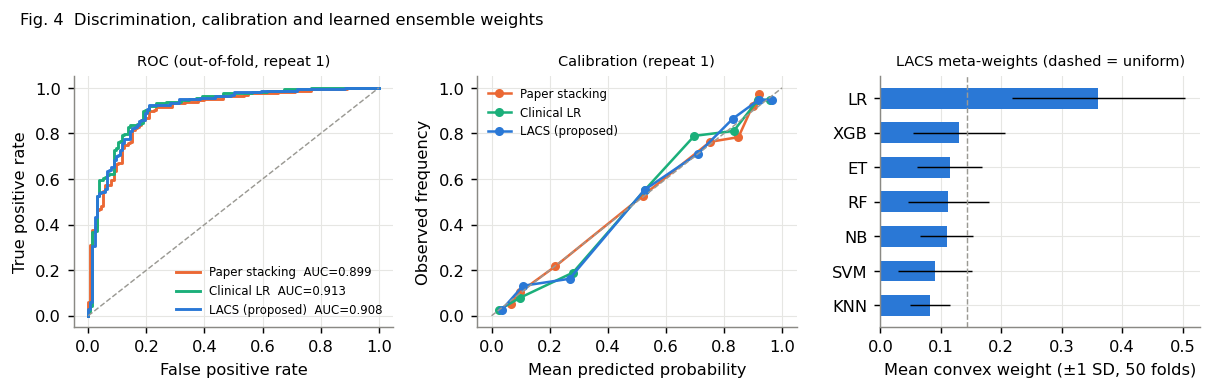

LR     0.361
SVM    0.091
KNN    0.082
NB     0.109
RF     0.113
ET     0.115
XGB    0.130
dtype: float64

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(9.4, 3.0))
y0 = yd
for m, col in [("Paper stacking (baseline)", ORANGE), ("Ablation: clinical LR only", AQUA), ("LACS (proposed)", BLUE)]:
    f, tp, _ = roc_curve(y0, oof_rep0[m]); from sklearn.metrics import roc_auc_score as _auc
    axs[0].plot(f, tp, color=col, lw=1.6, label=f"{short[m].replace(chr(10),' ')}  AUC={_auc(y0, oof_rep0[m]):.3f}")
    fp, mp = calibration_curve(y0, oof_rep0[m], n_bins=8, strategy="quantile")
    axs[1].plot(mp, fp, marker="o", ms=4, lw=1.4, color=col, label=short[m].replace(chr(10), " "))
axs[0].plot([0, 1], [0, 1], ls="--", color=GREY, lw=.8); axs[0].set_xlabel("False positive rate"); axs[0].set_ylabel("True positive rate")
axs[0].legend(fontsize=6.5, frameon=False, loc="lower right"); axs[0].set_title("ROC (out-of-fold, repeat 1)", fontsize=8)
axs[1].plot([0, 1], [0, 1], ls="--", color=GREY, lw=.8); axs[1].set_xlabel("Mean predicted probability"); axs[1].set_ylabel("Observed frequency")
axs[1].legend(fontsize=6.5, frameon=False, loc="upper left"); axs[1].set_title("Calibration (repeat 1)", fontsize=8)
wm = weights.mean().sort_values(); axs[2].barh(wm.index, wm.values, xerr=weights.std()[wm.index], color=BLUE, height=.6, error_kw={"elinewidth": .8})
axs[2].axvline(1 / len(wm), color=GREY, ls="--", lw=.8); axs[2].set_xlabel("Mean convex weight (±1 SD, 50 folds)")
axs[2].set_title("LACS meta-weights (dashed = uniform)", fontsize=8)
fig.suptitle("Fig. 4  Discrimination, calibration and learned ensemble weights", x=0.02, ha="left", fontsize=9)
plt.tight_layout(); plt.savefig("figures/fig4_roc_calib_weights.png"); plt.show()
weights.mean().round(3)

### 2.2 Sanity check: LACS under the paper's leaky protocol
If the leaky protocol cannot tell models apart (everything ≈ 100 %), it is not a valid benchmark.

In [14]:
lk = []
for s in range(10):
    a, b, c, d = train_test_split(X, y, test_size=0.2, stratify=y, random_state=s)
    lk.append({"seed": s, "Paper stacking": scores(d, paper_stacking(s).fit(a, c).predict_proba(b)[:, 1])["Accuracy"],
               "LACS": scores(d, ConvexStacking(seed=s).fit(a, c).predict_proba(b)[:, 1])["Accuracy"]})
lk = pd.DataFrame(lk); lk.to_csv("results/part2_leaky_protocol_check.csv", index=False); lk.describe().loc[["mean", "std", "min", "max"]].round(4)

,seed,Paper stacking,LACS
mean,4.5000,0.9956,0.9985
std,3.0277,0.0099,0.0046
min,0.0000,0.9707,0.9854
max,9.0000,1.0000,1.0000


### 2.3 Summary table for the report

In [15]:
final = pf.groupby("Model")[M].mean().loc[order2].round(4)
final.to_csv("results/part2_means.csv"); final

,Accuracy,Precision,Recall,F1,AUC,LogLoss,Brier
Model,,,,,,,
Paper stacking (baseline),0.8314,0.8261,0.8788,0.8500,0.9055,0.3987,0.1238
Paper best single (RF),0.8176,0.8145,0.8647,0.8371,0.9027,0.4075,0.1282
Ablation: paper stacking + clinical enc.,0.8357,0.8320,0.8775,0.8527,0.9069,0.3893,0.1195
Ablation: uniform soft vote,0.8444,0.8317,0.8976,0.8619,0.9124,0.3788,0.1176
"Ablation: convex, no shrinkage",0.8493,0.8394,0.8963,0.8655,0.9117,0.3793,0.1175
Ablation: clinical LR only,0.8549,0.8428,0.9042,0.8710,0.9162,0.3722,0.1148
LACS (proposed),0.8463,0.8345,0.8975,0.8633,0.9128,0.3779,0.1170
